<a href="https://colab.research.google.com/github/naubergois/curso-yolo-colab/blob/main/exercicios/aula1-exercicio6-recortar-o-onibus.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Aula 1, exercício 6: Recortar o ônibus

Recorte só o ônibus da imagem original. Leia a foto com `cv2.imread`, ache a caixa da classe `bus` e fatie o array. A resposta é o recorte.

O exercício é da aula [1. Detecção em imagem](https://colab.research.google.com/github/naubergois/curso-yolo-colab/blob/main/notebooks/01-deteccao-em-imagem.ipynb), e este notebook roda sozinho. Use **Ambiente de execução → Executar tudo**: ele prepara os dados, deixa uma célula para você tentar e, no fim, mostra uma solução já conferida.

In [1]:
!pip install -q ultralytics

In [2]:
import base64
import subprocess
import urllib.request
from pathlib import Path

from IPython.display import HTML, display


def baixar(url, destino):
    if not Path(destino).exists():
        urllib.request.urlretrieve(url, destino)
    print(f"{destino}: {Path(destino).stat().st_size / 1e6:.1f} MB")
    return destino


def mostrar_video(caminho, largura=720):
    """Converte para H.264 (o navegador não toca mp4v) e embute no notebook."""
    web = str(Path(caminho).with_suffix("")) + "_web.mp4"
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", caminho,
         "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", web],
        check=True,
    )
    dados = base64.b64encode(Path(web).read_bytes()).decode()
    display(HTML(f'<video width="{largura}" controls autoplay muted loop>'
                 f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))
    return web


def baixar_para_maquina(caminho):
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print(f"Fora do Colab: o arquivo está em {Path(caminho).resolve()}")

## Preparação

A preparação carrega o YOLOv8 e roda a detecção na foto do ônibus, como na aula 1. É dela que saem as caixas usadas no exercício.

bus.jpg: 0.1 MB


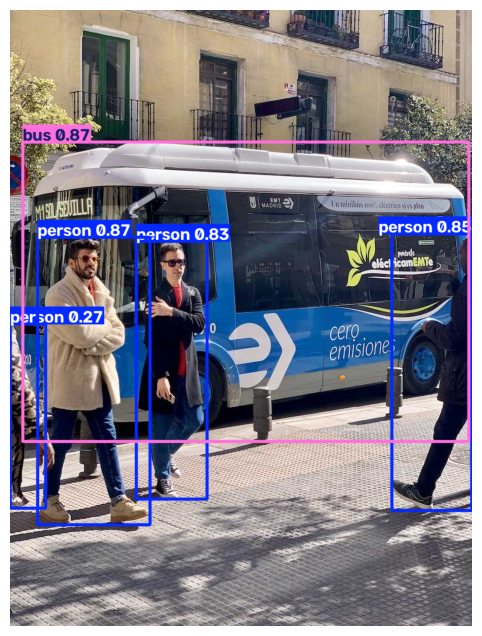

5 objetos detectados


In [3]:
from ultralytics import YOLO
import matplotlib.pyplot as plt

model = YOLO("yolov8n.pt")
imagem = baixar("https://ultralytics.com/images/bus.jpg", "bus.jpg")
resultado = model(imagem, verbose=False)[0]

plt.figure(figsize=(6, 8))
plt.imshow(resultado.plot()[:, :, ::-1])
plt.axis("off")
plt.show()
print(len(resultado.boxes), "objetos detectados")

In [4]:
# @title Correção automática (rode, não precisa ler)
import cv2

_cls = resultado.boxes.cls.int().tolist()
_conf = resultado.boxes.conf.tolist()
_xyxy = resultado.boxes.xyxy.tolist()


def _tamanho_onibus():
    i = [k for k, c in enumerate(_cls) if model.names[c] == "bus"][0]
    x1, y1, x2, y2 = map(int, _xyxy[i])
    return y2 - y1, x2 - x1


VERIFICAR = {
    1: lambda r: int(r) == _cls.count(0),
    2: lambda r: set(r) == {model.names[c] for c in _cls},
    3: lambda r: abs(float(r) - max(_conf)) < 1e-3,
    4: lambda r: abs(float(r) - max((c[2] - c[0]) * (c[3] - c[1]) for c in _xyxy)) < 1,
    5: lambda r: int(r) == len(model(imagem, classes=[0], verbose=False)[0].boxes),
    6: lambda r: all(abs(a - b) <= 2 for a, b in zip(r.shape[:2], _tamanho_onibus())),
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

## Sua vez

Recorte só o ônibus da imagem original. Leia a foto com `cv2.imread`, ache a caixa da classe `bus` e fatie o array. A resposta é o recorte.

*Dica:* Uma imagem do OpenCV é um array [linhas, colunas]: img[y1:y2, x1:x2].

Troque o `None` pela sua resposta e rode a célula.

In [5]:
resposta = None

conferir(6, resposta)

Exercício 6: ainda sem resposta.


## Uma solução

Compare com o que você fez. Existem outros caminhos certos: o que vale é a `conferir` aprovar.

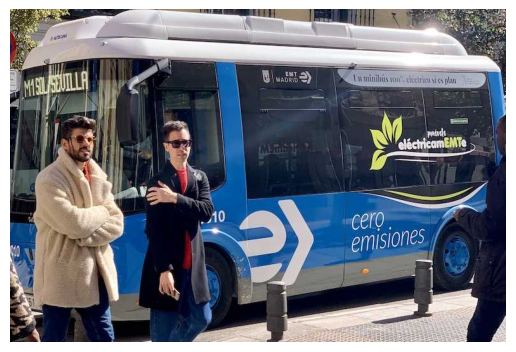

Exercício 6: ✅ certo!


In [6]:
img = cv2.imread(imagem)
i = [k for k, c in enumerate(resultado.boxes.cls) if model.names[int(c)] == "bus"][0]
x1, y1, x2, y2 = map(int, resultado.boxes.xyxy[i])
resposta = img[y1:y2, x1:x2]

plt.imshow(resposta[:, :, ::-1])
plt.axis("off")
plt.show()

conferir(6, resposta)

## O que fica

Próximo: [Aula 2, exercício 1: Duração do vídeo](https://colab.research.google.com/github/naubergois/curso-yolo-colab/blob/main/exercicios/aula2-exercicio1-duracao-do-video.ipynb).